# Course 2 — TensorFlow & Neural Networks

Concepts: Sequential API, Dense layers, ReLU, Softmax, training loops.


In [1]:
import sys
from pathlib import Path
# Add repository root to sys.path dynamically
project_root = Path(".").resolve()
while project_root.name and not (project_root / "utils").is_dir():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_moons

# Set random seed for reproducibility
tf.random.set_seed(42)

print(f"TensorFlow version: {tf.__version__}")


TensorFlow version: 2.21.0


## 1. Basic Dense Network (Binary Classification)
Building a binary classification neural network using Keras Sequential API.


── Binary Classification ──
Test accuracy: 0.980


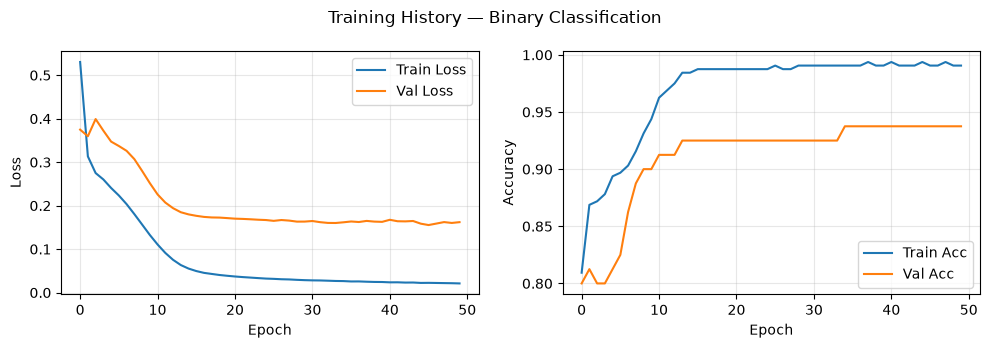

In [2]:
print("── Binary Classification ──")

X, y = make_moons(n_samples=500, noise=0.2, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = tf.keras.Sequential([
    tf.keras.layers.Dense(25, activation="relu",   name="layer1"),
    tf.keras.layers.Dense(15, activation="relu",   name="layer2"),
    tf.keras.layers.Dense(1,  activation="sigmoid", name="output"),
], name="binary_model")

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.01),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

history = model.fit(X_train, y_train, epochs=50, verbose=0, validation_split=0.2)

loss, acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Test accuracy: {acc:.3f}")

# Plot training history
plt.figure(figsize=(10, 3.5))
plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Val Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Train Acc")
plt.plot(history.history["val_accuracy"], label="Val Acc")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.suptitle("Training History — Binary Classification")
plt.tight_layout()
plt.show()


## 2. Multiclass Classification (Softmax)
Multiclass classification using Softmax activation and SparseCategoricalCrossentropy.


In [3]:
print("\n── Multiclass Classification ──")
from sklearn.datasets import make_classification

X_mc, y_mc = make_classification(n_samples=500, n_features=4,
                                  n_classes=3, n_clusters_per_class=1,
                                  n_redundant=0, random_state=42)
X_mc_train, X_mc_test, y_mc_train, y_mc_test = train_test_split(
    X_mc, y_mc, test_size=0.2, random_state=42
)

mc_model = tf.keras.Sequential([
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(3,  activation="softmax"),   # 3 classes
])

mc_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

mc_model.fit(X_mc_train, y_mc_train, epochs=30, verbose=0, validation_split=0.2)
mc_loss, mc_acc = mc_model.evaluate(X_mc_test, y_mc_test, verbose=0)
print(f"Multiclass test accuracy: {mc_acc:.3f}")



── Multiclass Classification ──
Multiclass test accuracy: 0.890


## 3. Model Architecture Summary


In [4]:
print("\n── Model Architecture ──")
model.summary()



── Model Architecture ──


Model: "binary_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ layer1 (Dense)                  │ (32, 25)               │            75 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer2 (Dense)                  │ (32, 15)               │           390 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (32, 1)                │            16 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,445 (5.65 KB)

 Trainable params: 481 (1.88 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 964 (3.77 KB)

## Key Takeaways


In [5]:
print("""
╔══ Key Takeaways ───────────────────────────────────────────────╗
║ • Sequential API: stack layers with .add() or list at init    ║
║ • Dense layer: y = activation(W·x + b)                       ║
║ • ReLU → hidden layers (avoids vanishing gradient)            ║
║ • Sigmoid → binary output (1 neuron, 0-1)                    ║
║ • Softmax → multiclass (C neurons, sum to 1)                 ║
║ • losses: BinaryCrossentropy, CategoricalCrossentropy,        ║
║   SparseCategoricalCrossentropy (when labels are integers)    ║
║ • Adam: adaptive learning rate — usually works out of box    ║
╚════════════════════════════════════════════════════════════════╝
""")



╔══ Key Takeaways ───────────────────────────────────────────────╗
║ • Sequential API: stack layers with .add() or list at init    ║
║ • Dense layer: y = activation(W·x + b)                       ║
║ • ReLU → hidden layers (avoids vanishing gradient)            ║
║ • Sigmoid → binary output (1 neuron, 0-1)                    ║
║ • Softmax → multiclass (C neurons, sum to 1)                 ║
║ • losses: BinaryCrossentropy, CategoricalCrossentropy,        ║
║   SparseCategoricalCrossentropy (when labels are integers)    ║
║ • Adam: adaptive learning rate — usually works out of box    ║
╚════════════════════════════════════════════════════════════════╝

